# **Практика 2. Первые шаги в парсинге — подключаемся к интернету**

**Цель:** научиться получать данные из интернета с помощью Python и собирать новости автоматически.


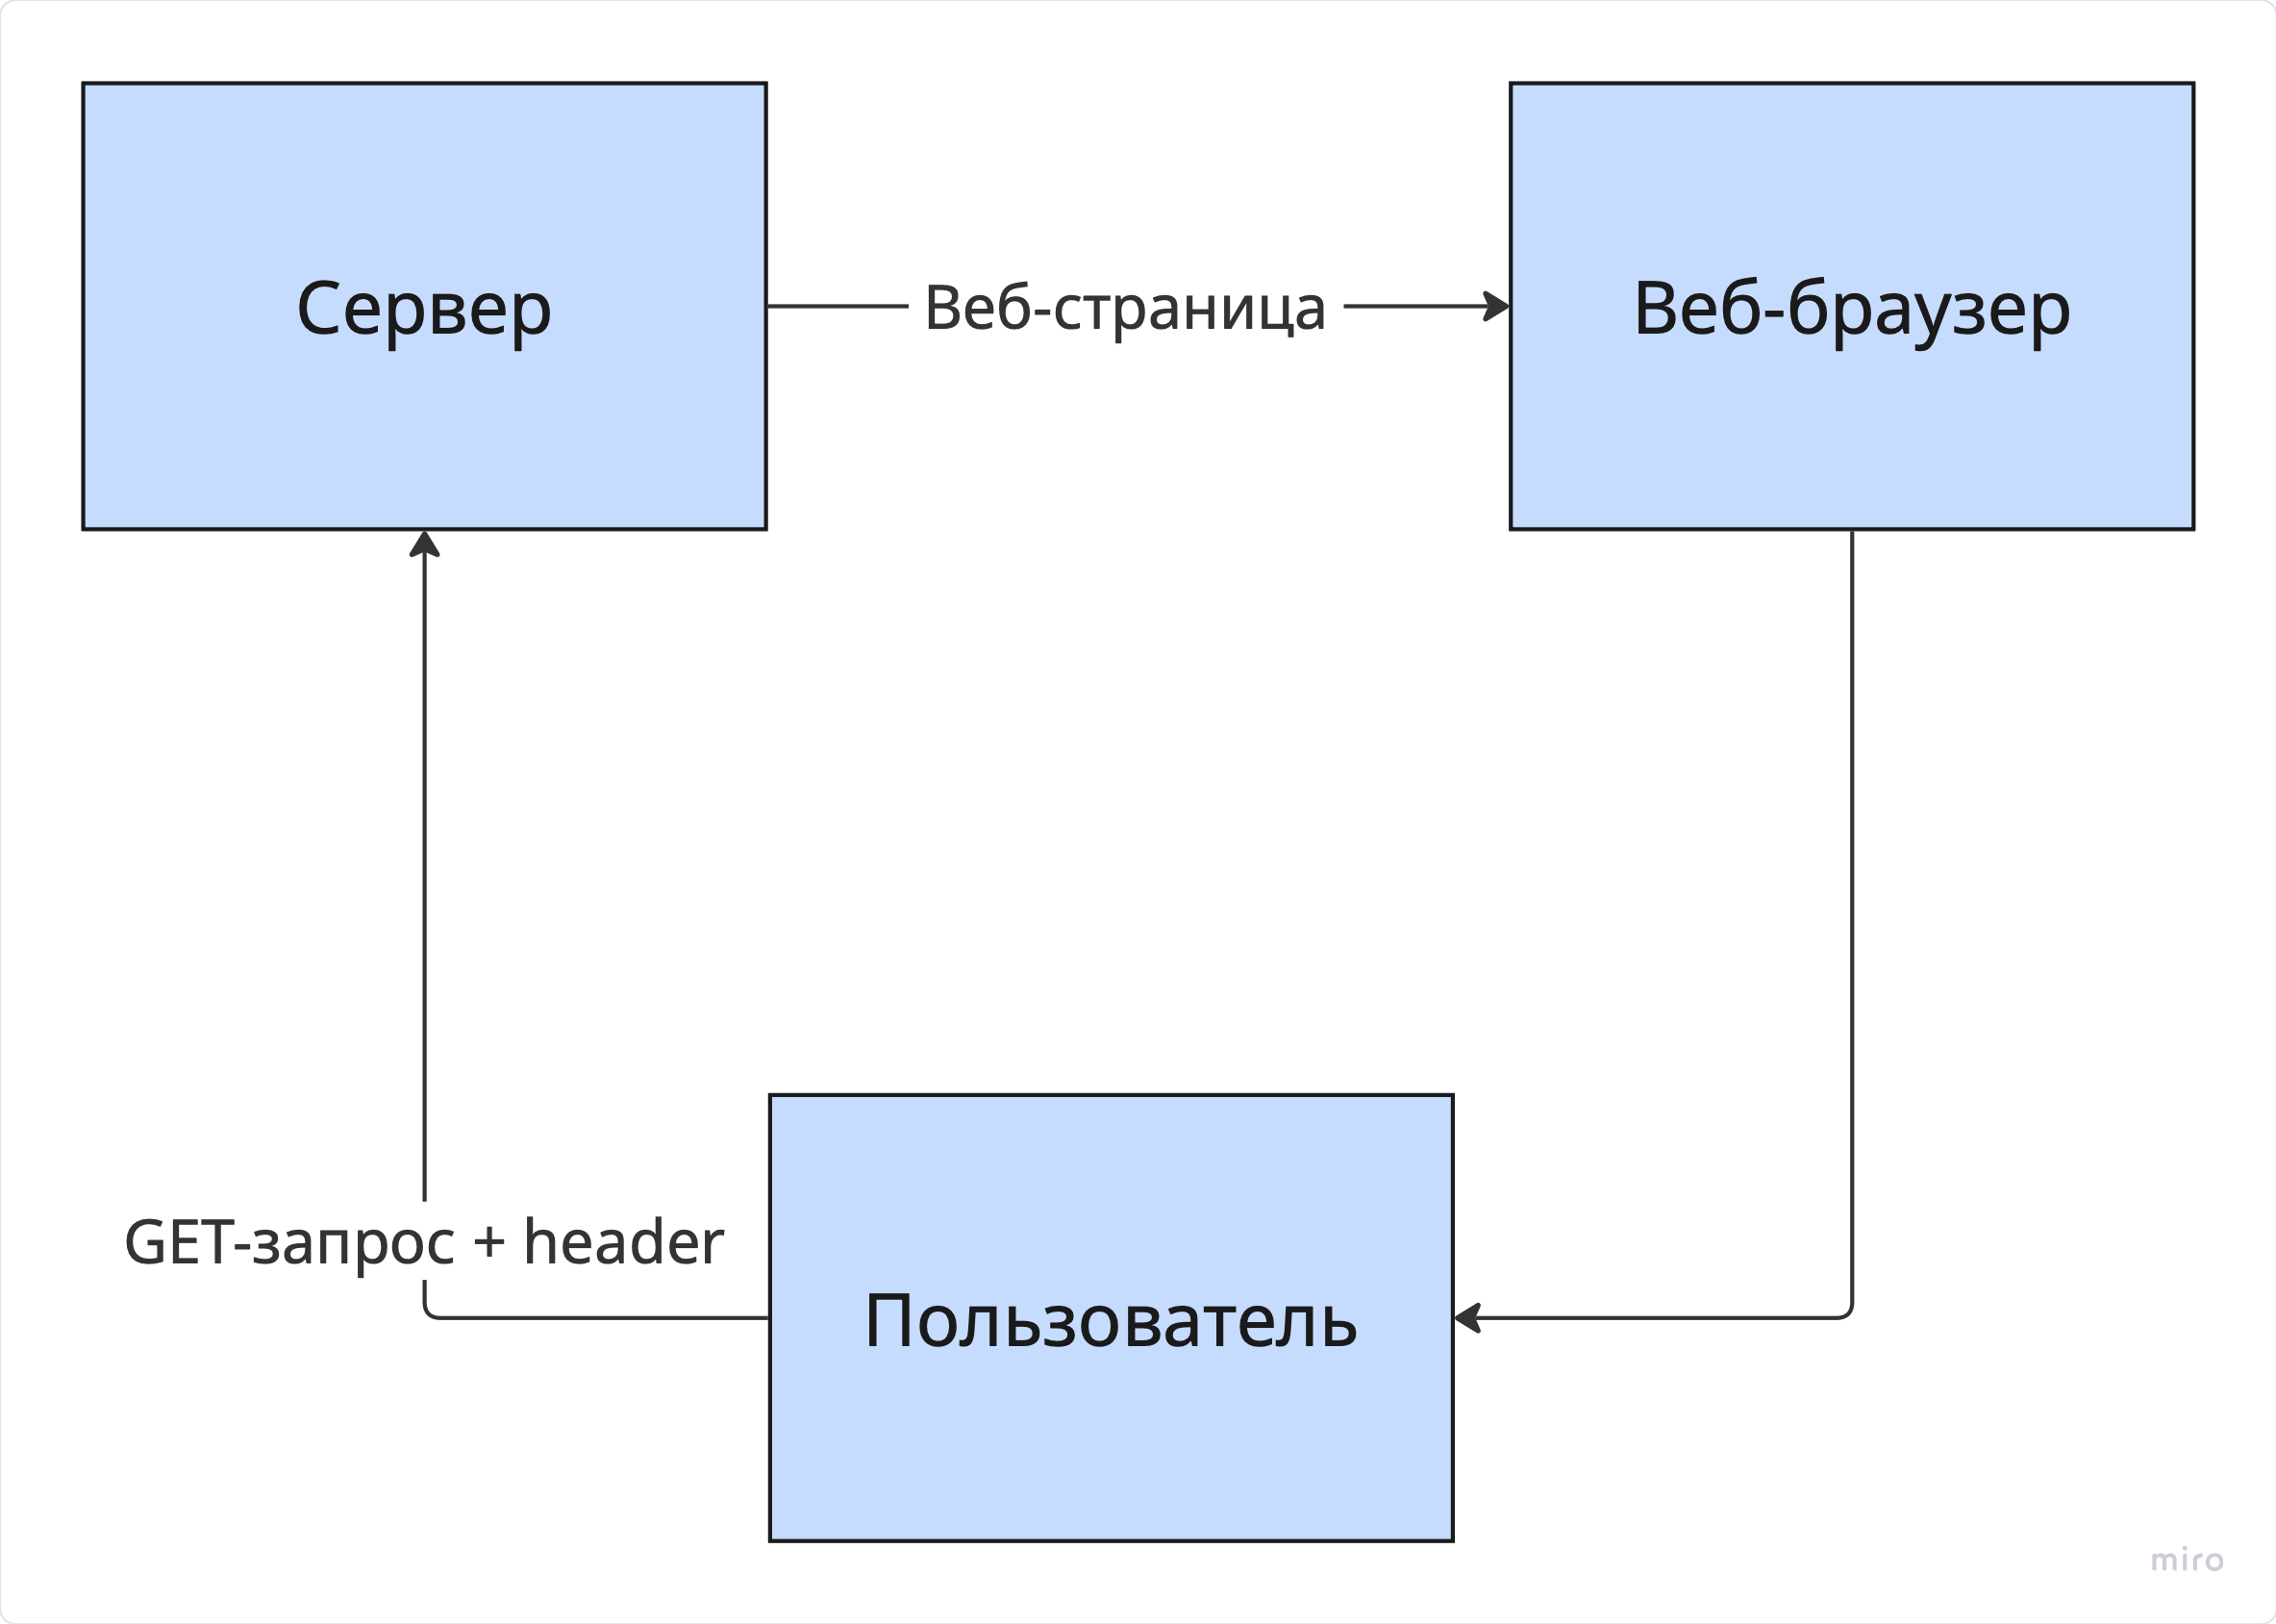

**GET-запрос** - разновидность HTTP-запроса к серверу, предполагащая получение ресурса

**header** - информация о клиенте (пользователе) и содержимом запроса.

---
## Часть 1: Как Python «ходит» в интернет

In [ ]:
# Устанавливаем нужные библиотеки
!pip install requests feedparser -q
print("Готово!")

### Что такое `requests`

Библиотека `requests` позволяет Python делать HTTP-запросы — то же самое, что делает браузер, когда вы открываете страницу. Разница: браузер показывает картинку, а `requests` возвращает «сырой» HTML или данные.

In [ ]:
import requests

# Делаем запрос к сайту
response = requests.get("https://httpbin.org/get")

# Проверяем статус
print(f"Статус: {response.status_code}")  # 200 = успех
print(f"Размер ответа: {len(response.text)} символов")
print("\nПервые 300 символов ответа:")
print(response.text[:300])

**Статусы HTTP — что означают:**
- `200` — всё хорошо, данные получены
- `403` — доступ запрещён (сайт блокирует ботов)
- `404` — страница не найдена
- `429` — слишком много запросов, нужна пауза
- `500` — ошибка на стороне сервера

---
## Часть 2: RSS-ленты — самый удобный способ получать новости

### Что такое RSS

RSS — специальный формат, который большинство СМИ специально создают для программного чтения. Это структурированный XML с заголовками, датами и ссылками на статьи.

Российские СМИ с RSS-лентами:
- Коммерсантъ: `https://www.kommersant.ru/RSS/main.xml`
- Lenta.ru: `https://lenta.ru/rss/news`
- РБК: `https://rssexport.rbc.ru/rbcnews/news/20/full.rss`
- ТАСС: `https://tass.ru/rss/v2.xml`
- Ведомости: `https://www.vedomosti.ru/rss/news`

In [ ]:
import feedparser

# Читаем RSS-ленту Lenta.ru
rss_url = "https://lenta.ru/rss/news"
feed = feedparser.parse(rss_url)

print(f"Источник: {feed.feed.get('title', 'Без названия')}")
print(f"Количество новостей: {len(feed.entries)}")
print("\nПервые 5 заголовков:")
for i, entry in enumerate(feed.entries[:5], 1):
    print(f"{i}. {entry.title}")

In [ ]:
# Смотрим подробно на одну новость
first_entry = feed.entries[0]

print("Поля одной новости:")
print(f"Заголовок: {first_entry.get('title', 'нет')}")
print(f"Ссылка: {first_entry.get('link', 'нет')}")
print(f"Дата: {first_entry.get('published', 'нет')}")
print(f"Краткое содержание: {first_entry.get('summary', 'нет')[:200]}")

In [ ]:
feed.entries[0]

### Как найти RSS-ленту?

1. Открыть исходный код страницы и поискать там ссылку со словом "rss".
2. Поискать на страницах сайта значок RSS (см. фото ниже).
3. Воспользоваться специальными сервисами для поиска RSS-лент, например: https://lighthouseapp.io/tools/feed-finder

---
## Часть 3: Фильтрация по ключевым словам

In [ ]:
# Задаём ключевые слова для мониторинга
# ЗАДАНИЕ: замените на свой бренд или тему

KEYWORDS = ["Россия", "россия"]

def find_mentions(entries, keywords):
    """Находит новости, содержащие ключевые слова."""
    mentions = []
    keywords_lower = [kw.lower() for kw in keywords]

    for entry in entries:
        # Берём заголовок и краткое содержание
        text = (entry.get('title', '') + ' ' + entry.get('summary', '')).lower()

        # Проверяем каждое ключевое слово
        for keyword in keywords_lower:
            if keyword in text:
                mentions.append({
                    'title': entry.get('title', ''),
                    'link': entry.get('link', ''),
                    'date': entry.get('published', ''),
                    'summary': entry.get('summary', '')[:200],
                    'matched_keyword': keyword
                })
                break  # Не добавляем дважды если несколько совпадений

    return mentions

mentions = find_mentions(feed.entries, KEYWORDS)
print(f"Найдено упоминаний: {len(mentions)} из {len(feed.entries)} новостей")

for m in mentions[:5]:
    print(f"\n {m['title']}")
    print(f"   Ключевое слово: {m['matched_keyword']}")
    print(f"   Ссылка: {m['link']}")

---
## Часть 4: Сбор из нескольких источников

In [ ]:
import time

# Список RSS-источников
RSS_FEEDS = [
    "https://lenta.ru/rss/news",
    "https://tass.ru/rss/v2.xml"
]

def collect_from_all_sources(rss_urls, keywords):
    """Собирает упоминания из нескольких RSS-источников."""
    all_mentions = []

    for url in rss_urls:
        print(f"Обрабатываю: {url}...")
        try:
            feed = feedparser.parse(url)
            source_name = feed.feed.get('title', url)

            mentions = find_mentions(feed.entries, keywords)

            # Добавляем источник к каждому упоминанию
            for m in mentions:
                m['source'] = source_name

            all_mentions.extend(mentions)
            print(f"  → Найдено: {len(mentions)} упоминаний")

        except Exception as e:
            print(f" Ошибка: {e}")

        time.sleep(1)  # Вежливая пауза между запросами

    return all_mentions

all_mentions = collect_from_all_sources(RSS_FEEDS, KEYWORDS)
print(f"\nИТОГО: {len(all_mentions)} упоминаний из {len(RSS_FEEDS)} источников")

---
## Часть 5: Сохранение в CSV

In [ ]:
import csv
from datetime import datetime

def save_to_csv(mentions, filename=None):
    """Сохраняет упоминания в CSV-файл."""
    if filename is None:
        filename = f"mentions_{datetime.now().strftime('%Y%m%d_%H%M')}.csv"

    if not mentions:
        print("Нет данных для сохранения")
        return

    fieldnames = ['title', 'source', 'date', 'link', 'summary', 'matched_keyword']

    with open(filename, 'w', newline='', encoding='utf-8') as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames, extrasaction='ignore')
        writer.writeheader()
        writer.writerows(mentions)

    print(f" Сохранено {len(mentions)} записей в файл: {filename}")
    return filename

# Сохраняем
csv_file = save_to_csv(all_mentions)

In [ ]:
# Скачиваем файл из Colab
from google.colab import files
if csv_file:
    files.download(csv_file)

---
## Итоговое заданиеё

Модифицируйте код выше:

1. **Замените ключевые слова** на свой бренд или тему (можно выдуманную)
2. **Добавьте третий RSS-источник** из списка выше
3. **Добавьте поле `urgency`** — если заголовок содержит слова «скандал», «кризис», «иск», «утечка» → значение `'high'`, иначе `'normal'`

Подсказка для пункта 3:
```python
urgent_words = ['скандал', 'кризис', 'иск', 'утечка', 'авария']
title_lower = mention['title'].lower()
mention['urgency'] = 'high' if any(w in title_lower for w in urgent_words) else 'normal'
```
Проанализируйте результаты. Если вы использовали ИИ, не забудьте указать это (надо подробно описать для чего и какой ИИ был использован).